# Example 03: Fourier amplitude spectra and $\kappa$

Fourier amplitude spectrum models give the amplitude of the Fourier transform of the acceleration, which is the input of random vibration theory. This example compares three of them for one earthquake, shows the site attenuation $\kappa_0$ from the two relationships in `pygmm.kappa`, and uses a source-theory spectrum to compute a response spectrum with pyRVT.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygmm
from pygmm import fourier_spectrum, kappa

%matplotlib inline

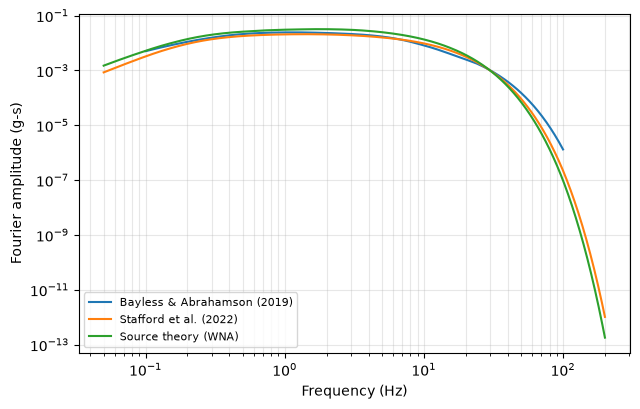

In [2]:
scenario = pygmm.Scenario(
    mag=6.5,
    dist_rup=20.0,
    dist_jb=20.0,
    dist_x=20.0,
    dip=90.0,
    mechanism="SS",
    v_s30=760.0,
)

models = {
    "Bayless & Abrahamson (2019)": fourier_spectrum.BaylessAbrahamson2019(
        scenario.copy_with(depth_tor=0.0)
    ),
    "Stafford et al. (2022)": fourier_spectrum.StaffordEtAl2022(
        mag=6.5, dist_rup=20.0, dist_jb=20.0, mechanism="SS"
    ),
    "Source theory (WNA)": fourier_spectrum.SourceTheoryModel(
        magnitude=6.5, distance=20.0, region="wna"
    ),
}

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name, m in models.items():
    ax.plot(m.freqs, m.fourier_amps, label=name)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Frequency (Hz)",
    ylabel="Fourier amplitude (g-s)",
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

## Site attenuation

$\kappa_0$ from $V_{s30}$ (Van Houtte et al., 2011; Xu and Rathje, 2021). The attenuation of a Fourier spectrum is $\exp(-\pi \kappa_0 f)$.

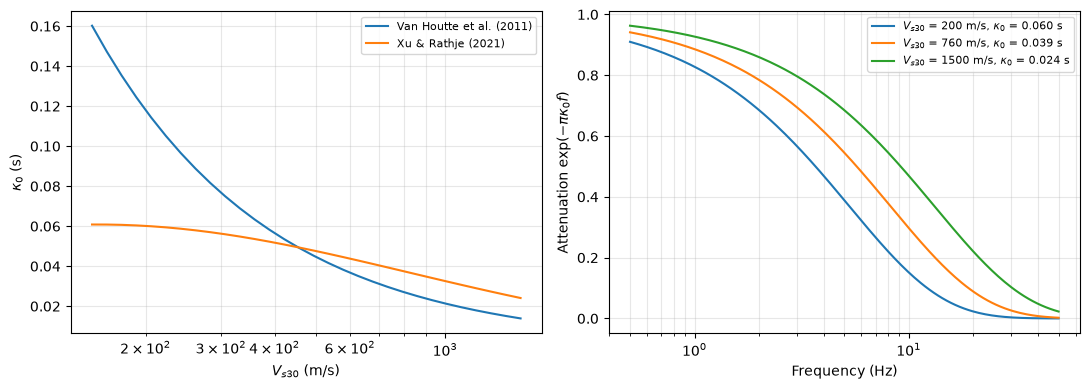

In [3]:
vs30 = np.geomspace(150.0, 1500.0, 30)
freqs = np.geomspace(0.5, 50.0, 200)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(vs30, kappa.calc_site_atten_vhea11(vs30), label="Van Houtte et al. (2011)")
axes[0].plot(vs30, kappa.calc_site_atten_xr21(vs30), label="Xu & Rathje (2021)")
axes[0].set(xscale="log", xlabel="$V_{s30}$ (m/s)", ylabel="$\\kappa_0$ (s)")
for v in [200.0, 760.0, 1500.0]:
    k = kappa.calc_site_atten_xr21(v)
    axes[1].plot(
        freqs,
        np.exp(-np.pi * k * freqs),
        label=f"$V_{{s30}}$ = {v:.0f} m/s, $\\kappa_0$ = {k:.3f} s",
    )
axes[1].set(
    xscale="log",
    xlabel="Frequency (Hz)",
    ylabel="Attenuation $\\exp(-\\pi \\kappa_0 f)$",
)
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()

## Response spectrum from a Fourier spectrum

The source-theory model has the Fourier amplitudes and the duration that random vibration theory needs. `RvtMotion.from_fas` computes the peak response, and the response spectrum is that of the motion.

PGA: 0.143 g, duration: 6.1 s


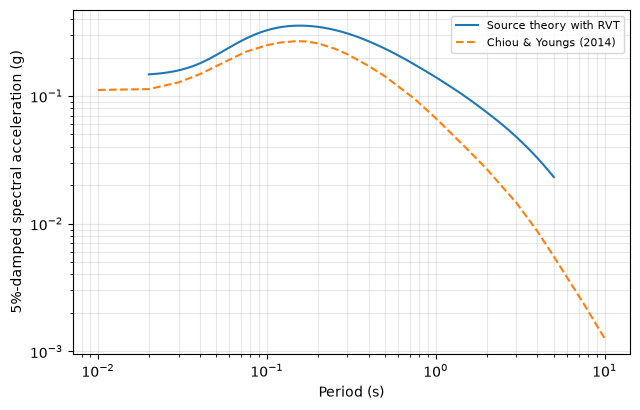

In [4]:
import pyrvt

fas = models["Source theory (WNA)"]
motion = pyrvt.motions.RvtMotion.from_fas(fas)
osc_freqs = np.geomspace(0.2, 50.0, 80)
osc_accels = motion.calc_osc_accels(osc_freqs, 0.05)

gmm = pygmm.ChiouYoungs2014(scenario)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(1 / osc_freqs, osc_accels, label="Source theory with RVT")
ax.plot(gmm.periods, gmm.spec_accels, "--", label="Chiou & Youngs (2014)")
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Period (s)",
    ylabel="5%-damped spectral acceleration (g)",
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
print(f"PGA: {motion.pga:.3f} g, duration: {fas.duration:.1f} s")

### Observations

- **The three Fourier spectra are within a factor of 1.7 of each other from 0.1 to 30 Hz** for this earthquake, and diverge at higher frequencies, where the decay is controlled by $\kappa_0$ and the site amplification of each model; at 100 Hz the largest is 14 times the smallest. The range of the Bayless and Abrahamson (2019) model ends at 100 Hz.
- **The two $\kappa_0$ relationships agree near 450 m/s.** Below it Van Houtte et al. (2011) is larger (0.16 s at 150 m/s against 0.06 s) and above it Xu and Rathje (2021) is larger (0.039 s against 0.029 s at 760 m/s). The attenuation $\exp(-\pi \kappa_0 f)$ halves the spectrum at 3.7 Hz for 0.06 s and at 9.2 Hz for 0.024 s.
- **The response spectrum from the source-theory model** (PGA 0.14 g, duration 6.1 s) is about twice that of Chiou and Youngs (2014) at 1 s. The models have different site conditions and path assumptions, so this is a comparison of the two rather than a check of either.